# 02 · Preparación de los datos para los modelos

Tenemos variables **numéricas** (montos, plazos, días) y **categóricas** (modalidad, tipo de contrato…). Antes de usar DBSCAN y K-prototypes hay que:

1. llenar los vacíos numéricos,
2. poner las numéricas en la misma escala,
3. convertir las categorías a números,
4. definir **cómo medir la distancia** entre dos contratos.

Usamos **la misma distancia en DBSCAN y en K-prototypes**. Así, si los dos métodos encuentran atípicos distintos, es por cómo funciona cada algoritmo y no porque midan distinto.

In [ ]:
from pathlib import Path

RAIZ = Path("..")
DATA = RAIZ / "data"
MUESTRAS = DATA / "muestras"
RESULTADOS = RAIZ / "resultados"
MODELOS = RESULTADOS / "modelos"
FIGURAS = RESULTADOS / "figuras"
TABLAS = RESULTADOS / "tablas"
for carpeta in [MUESTRAS, MODELOS, FIGURAS, TABLAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

NUMERICAS = [
    "log_valor_contrato",          # log(1 + valor del contrato)
    "log_ratio_contrato_proceso",  # log(valor del contrato / valor estimado del proceso)
    "ratio_adiciones",             # valor adicionado / valor del contrato
    "log_plazo_dias",              # log(1 + plazo en días)
    "log_adiciones_dias",          # log(1 + días adicionados)
    "slog_dias_firma_cargue",      # log "con signo" de los días entre la firma y la publicación
]
CATEGORICAS = [
    "modalidad_de_contratacion",
    "tipo_de_contrato",
    "orden_entidad",
    "nombre_grupo",
    "tipo_identifi_del_contratista",
    "destino_gasto",
    "estado_del_proceso",
]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

limpia = pd.read_parquet(MUESTRAS / "muestra_limpia.parquet")
cruda = pd.read_parquet(MUESTRAS / "muestra_cruda.parquet")

cruda = cruda.drop(columns=NUMERICAS + CATEGORICAS)
cruda = cruda.rename(columns={"raw_" + c: c for c in NUMERICAS + CATEGORICAS})
print(cruda.shape, limpia.shape)

(50000, 29) (50000, 42)


## 1. ¿Qué cambia entre los datos crudos y los limpios?

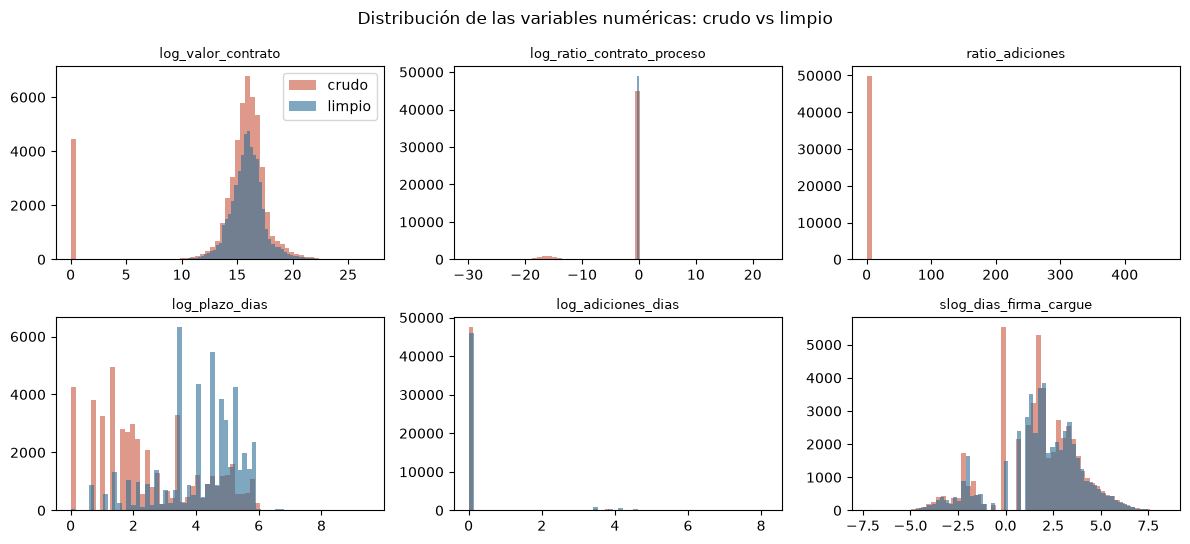

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for ax, col in zip(axes.ravel(), NUMERICAS):
    ax.hist(cruda[col], bins=60, alpha=0.6, label="crudo", color="#c8553d")
    ax.hist(limpia[col].dropna(), bins=60, alpha=0.6, label="limpio", color="#2a6f97")
    ax.set_title(col, fontsize=9)
axes[0, 0].legend()
plt.suptitle("Distribución de las variables numéricas: crudo vs limpio")
plt.tight_layout()
plt.savefig(FIGURAS / "variables_crudo_vs_limpio.png", dpi=130)
plt.show()

In [3]:
pd.DataFrame({
    "mediana cruda": cruda[NUMERICAS].median(),
    "mediana limpia": limpia[NUMERICAS].median(),
    "% ceros crudo": (cruda[NUMERICAS] == 0).mean() * 100,
    "% ceros limpio": (limpia[NUMERICAS] == 0).mean() * 100,
}).round(2)

,mediana cruda,mediana limpia,% ceros crudo,% ceros limpio
log_valor_contrato,15.81,15.94,8.94,0.00
log_ratio_contrato_proceso,0.00,0.00,82.06,90.28
ratio_adiciones,0.00,0.00,92.29,91.27
log_plazo_dias,2.08,4.51,8.51,0.07
log_adiciones_dias,0.00,0.00,95.35,91.79
slog_dias_firma_cargue,1.79,1.95,11.10,2.98


Se ve el efecto de la limpieza:

* En los datos crudos hay una **pila de ceros** (procesos sin contrato, con valor 0).
* El **plazo** crudo es mucho menor, porque "5 meses" se lee como "5".

## 2. Transformaciones

* **Vacíos numéricos:** se llenan con la mediana (`SimpleImputer`).
* **Escala:** `StandardScaler` deja cada variable con media 0 y desviación 1. Así ninguna pesa más solo por sus unidades.
* **Categorías → códigos:** `OrdinalEncoder` asigna un número a cada categoría. Las categorías muy raras (menos del 0,1 % de la muestra) se agrupan en una sola (`min_frequency`). Si en otros datos aparece una categoría nueva, recibe el código -1.

## 3. La distancia entre dos contratos

K-prototypes (Huang, 1998) mide la distancia entre dos contratos así:

$$d(a, b) = \underbrace{\sum_{\text{numéricas}} (a_j - b_j)^2}_{\text{diferencia en números}} \;+\; \gamma \cdot \underbrace{\#\{\text{categorías distintas}\}}_{\text{diferencia en categorías}}$$

* $\gamma$ dice cuánto "pesa" una categoría distinta. Huang recomienda $\gamma = 0{,}5 \times$ (desviación promedio de las numéricas). Como estandarizamos, la desviación es 1, así que **$\gamma = 0{,}5$**.

**¿Y DBSCAN?** DBSCAN solo sabe usar distancia euclidiana sobre números. Truco: convertimos cada categoría en columnas 0/1 (**one-hot**) y multiplicamos esas columnas por $\sqrt{\gamma/2} = 0{,}5$.

Si dos contratos tienen una categoría distinta, difieren en **dos** columnas one-hot (un 1 que pasa a 0 y un 0 que pasa a 1). Cada una aporta $0{,}5^2 = 0{,}25$ a la distancia al cuadrado. En total: $2 \times 0{,}25 = 0{,}5 = \gamma$.

Es decir: **la distancia euclidiana al cuadrado que usa DBSCAN es exactamente la distancia de K-prototypes.** Lo comprobamos más abajo.

In [ ]:
GAMMA = 0.5

def preparar(datos):
    imputador = SimpleImputer(strategy="median").fit(datos[NUMERICAS])
    escalador = StandardScaler().fit(imputador.transform(datos[NUMERICAS]))
    codificador = OrdinalEncoder(min_frequency=0.001, handle_unknown="use_encoded_value",
                                 unknown_value=-1).fit(datos[CATEGORICAS].astype(str))

    X_num = escalador.transform(imputador.transform(datos[NUMERICAS]))
    X_cat = codificador.transform(datos[CATEGORICAS].astype(str)).astype(int)

    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_cat)
    Z = np.hstack([X_num, onehot.transform(X_cat) * np.sqrt(GAMMA / 2)])

    return {"datos": datos.reset_index(drop=True), "X_num": X_num, "X_cat": X_cat, "Z": Z,
            "imputador": imputador, "escalador": escalador, "codificador": codificador, "onehot": onehot}


prep_cruda = preparar(cruda)
prep_limpia = preparar(limpia)
print("Columnas para DBSCAN (crudo): ", prep_cruda["Z"].shape[1])
print("Columnas para DBSCAN (limpio):", prep_limpia["Z"].shape[1])

Columnas para DBSCAN (crudo):  63
Columnas para DBSCAN (limpio): 55


Comprobación: para los primeros 5 contratos calculamos la distancia **a mano** con la fórmula de K-prototypes y la comparamos con la euclidiana² sobre la matriz `Z`.

In [5]:
p = prep_limpia
for i in range(1, 6):
    a, b = 0, i
    d_kprototypes = ((p["X_num"][a] - p["X_num"][b]) ** 2).sum() + GAMMA * (p["X_cat"][a] != p["X_cat"][b]).sum()
    d_dbscan = ((p["Z"][a] - p["Z"][b]) ** 2).sum()
    print(f"contrato 0 vs {b}:  K-prototypes = {d_kprototypes:.4f}   euclidiana² en Z = {d_dbscan:.4f}")

contrato 0 vs 1:  K-prototypes = 1.9755   euclidiana² en Z = 1.9755
contrato 0 vs 2:  K-prototypes = 14.4027   euclidiana² en Z = 14.4027
contrato 0 vs 3:  K-prototypes = 16.7898   euclidiana² en Z = 16.7898
contrato 0 vs 4:  K-prototypes = 8.2581   euclidiana² en Z = 8.2581
contrato 0 vs 5:  K-prototypes = 11.5635   euclidiana² en Z = 11.5635


In [6]:
joblib.dump(prep_cruda, MODELOS / "preparacion_cruda.joblib")
joblib.dump(prep_limpia, MODELOS / "preparacion_limpia.joblib")
print("Guardado")

Guardado
